### Dependnecy Setup

In [102]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from datetime import datetime
import json

### Load Data

In [103]:
# Choose dataset B or C
DATA = "B"

In [104]:
df_gen_params = pd.read_csv(f'Data/Data{DATA}_generatorparams.csv', sep=';')
df_load = pd.read_csv(f'Data/Data{DATA}_hourlyload.csv', sep=';')
df_nondisp = pd.read_csv(f'Data/Data{DATA}_nondispgeneration.csv', sep=';')

# If DataC is in MW, convert to kW
# I BELIEVE!

# Kriss: I don't think this is a good idea, the penalties here are definedd in 1000 €/kW, 
# so if dataset C is in MW and we convert it,
# then the penalty for 1MW mismatch would be 2000 €/kW * 1000 kW = 2,000,000 €/MW which is way too high.

"""if DATA == "C":
    df_gen_params[['pmin', 'pmax']] *= 1000  # MW → kW
    df_load['load'] *= 1000  # MWh → kWh"""

'if DATA == "C":\n    df_gen_params[[\'pmin\', \'pmax\']] *= 1000  # MW → kW\n    df_load[\'load\'] *= 1000  # MWh → kWh'

## Sample multiple solar- and wind scenarios

In [105]:
# Change to test where optimality is guaranteed
num_scenarios = 500

In [106]:
# 1. Helper function to parse '0-5' into [0, 1, 2, 3, 4, 5]
def parse_hour_block(block_str):
    start, end = map(int, block_str.split('-'))
    return list(range(start, end + 1))

# 2. Create a lookup map: Hour (0-23)
hour_dist_map = {}
for block in df_nondisp['hour'].unique():
    hours_in_block = parse_hour_block(block)
    dist_rows = df_nondisp[df_nondisp['hour'] == block]
    for h in hours_in_block:
        hour_dist_map[h] = dist_rows

# 3. Generate Scenarios
np.random.seed(42) # Fixed seed for reproducibility
scenario_data = {} # This will store our data for the Pyomo model

for s in range(num_scenarios):
    # Lists to store the 24-hour profile for this specific scenario
    wind_profile = []
    solar_profile = []
    
    for h in range(24):
        dist = hour_dist_map[h]
        
        # Sample Wind
        # Normalize probs to avoid floating point errors (e.g., sum=0.999999)
        w_probs = dist['probability wind'].values / dist['probability wind'].values.sum()
        w_val = np.random.choice(dist['generation wind'].values, p=w_probs)
        wind_profile.append(w_val)
        
        # Sample Solar
        s_probs = dist['probability solar'].values / dist['probability solar'].values.sum()
        s_val = np.random.choice(dist['generation solar'].values, p=s_probs)
        solar_profile.append(s_val)
    
    # Store as a DataFrame (convenient for Pyomo indexing)
    scenario_data[s] = pd.DataFrame({
        'wind': wind_profile, 
        'solar': solar_profile
    })

# Check scenario
print(scenario_data[1])

    wind  solar
0     40      0
1    200      0
2    200      0
3     40      0
4     20      0
5     20      0
6     40     40
7    100     40
8     20     60
9     20     90
10    20     90
11   100     10
12    20    200
13   100    200
14   100     10
15    40     10
16   100     60
17    40     10
18    40     40
19   100     60
20   100      0
21    20      0
22   100      0
23   100      0


### Model Initialization

In [107]:
model = pyo.ConcreteModel(name="Unit Commitment Stage 1")

# Sets
model.S = pyo.Set(initialize=range(num_scenarios)) # Sample over 200 scenarios

# Generators [1, 2, 3]
model.G = pyo.Set(initialize=df_gen_params['generator'].tolist())

# Time steps [0, 1, ..., 23]
model.T = pyo.Set(initialize=range(24))

### Parameters

In [108]:
# Parameters for Generators 
model.a1 = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['a1'].to_dict())
model.a2 = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['a2'].to_dict())
model.p_min = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['pmin'].to_dict())
model.p_max = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['pmax'].to_dict())

# Parameters for Hourly Data 
# Create hourly load dict from df_load with index 0-23
hourly_load_init = {i: df_load['load'].iloc[i] for i in range(24)}
model.hourly_load = pyo.Param(model.T, initialize=hourly_load_init)

# Build initializer dicts for Pyomo Params
wind_init = {(t, s): scenario_data[s].loc[t, 'wind'] for s in model.S for t in model.T}
solar_init = {(t, s): scenario_data[s].loc[t, 'solar'] for s in model.S for t in model.T}

# Define Params with these initializers
model.wind_samples = pyo.Param(model.T, model.S, initialize=wind_init, within=pyo.NonNegativeReals)
model.solar_samples = pyo.Param(model.T, model.S, initialize=solar_init, within=pyo.NonNegativeReals)

### Decision Variables

In [109]:
# u[g, t]: Binary status of dispatchable generator g at time t (1 if on, 0 if off)
model.u = pyo.Var(model.G, model.T, domain=pyo.Binary)

# p[g, t]: Power output of dispatchable generator g at time t (non-negative) in scenario S
model.p = pyo.Var(model.G, model.T, model.S, domain=pyo.NonNegativeReals)

# u_wind[t], u_solar[t]: Binary status of non-dispatchable generators at time t
model.u_wind = pyo.Var(model.T, domain=pyo.Binary)
model.u_solar = pyo.Var(model.T, domain=pyo.Binary)

## Slack Variables

In [110]:
# surplus[t], deficit[t]: Surplus and deficit variables at time t 
# to ensure feasibility if production does not equal demand
model.surplus = pyo.Var(model.T, model.S, domain=pyo.NonNegativeReals)
model.deficit = pyo.Var(model.T, model.S, domain=pyo.NonNegativeReals)
model.p_min_slack = pyo.Var(model.G, model.T, model.S, domain=pyo.NonNegativeReals)
model.p_max_slack = pyo.Var(model.G, model.T, model.S, domain=pyo.NonNegativeReals)

# Min/Max violation slack variables (soft constraints)
# # p_max_slack[g,t,s]: Amount generator g goes above p_max at time t in scenario s
# p_min_slack[g,t,s]: Amount generator g goes below p_min at time t in scenario s

### Objective Function
Minimize the cost of power generators averaged over the scenarios S


Kriss: I slightly modified the cost function so we can change the weight of the power mismatch penalty to avoid violations. From my testing about 80/200 scenarios used to have at least one violation, which might be a bad idea if we switch to MW and dispatchable generators are worse at handling nondispatchable power in C dataset. Now only about ?/200 have violations.

In [111]:
# Weighted penalty parameters
penalty_weight = 1000  # Penalty per unit violation for load mismatch (€/kW)
penalty_min_max = 1000  # Penalty per unit violation for min/max constraint (€/kW)
generation_weight = 1.0  # Relative weight for generation costs

def objective_rule(m):
    total_expected_cost = 0
    for s in m.S:
        generation_cost = sum(m.a2[g] * m.p[g,t,s]**2 + m.a1[g] * m.p[g,t,s] for g in m.G for t in m.T)
        # Load mismatch penalty
        load_mismatch_penalty = sum(penalty_weight * (m.surplus[t,s] + m.deficit[t,s]) for t in m.T)
        # Min/Max constraint violation penalties
        minmax_penalty = sum(penalty_min_max * (m.p_min_slack[g,t,s] + m.p_max_slack[g,t,s]) for g in m.G for t in m.T)
        total_expected_cost += (generation_weight * generation_cost + load_mismatch_penalty + minmax_penalty)
    return total_expected_cost / len(m.S)

model.obj = pyo.Objective(rule=objective_rule, sense=pyo.minimize)

print(f"Objective weights: generation={generation_weight}, load_mismatch_penalty={penalty_weight}, min/max_penalty={penalty_min_max}")
print(f"Load mismatch penalty ratio: {penalty_weight / 1000:.0f}x the original")
print(f"Min/Max constraint penalty ratio: {penalty_min_max / 1000:.0f}x the original")

Objective weights: generation=1.0, load_mismatch_penalty=1000, min/max_penalty=1000
Load mismatch penalty ratio: 1x the original
Min/Max constraint penalty ratio: 1x the original


### Constraints

In [112]:
# Minimum Generation (soft constraint with slack)
def p_min_rule(m, g, t, s):
    return m.p[g, t, s] >= m.u[g, t] * m.p_min[g] - m.p_min_slack[g, t, s]
model.C_p_min = pyo.Constraint(model.G, model.T, model.S, rule=p_min_rule)

# Maximum Generation (soft constraint with slack)
def p_max_rule(m, g, t, s):
    return m.p[g, t, s] <= m.u[g, t] * m.p_max[g] + m.p_max_slack[g, t, s]
model.C_p_max = pyo.Constraint(model.G, model.T, model.S, rule=p_max_rule)

# Power Balance
def p_balance_rule(m, t, s):
    dispatchable_gen = sum(m.p[g, t, s] for g in m.G)
    nondispatchable_gen = (m.u_wind[t] * m.wind_samples[t, s]) + (m.u_solar[t] * m.solar_samples[t, s])

    return dispatchable_gen + nondispatchable_gen + m.surplus[t, s] - m.deficit[t, s] == m.hourly_load[t]
model.C_p_balance = pyo.Constraint(model.T, model.S, rule=p_balance_rule)

### Solving with NEOS

In [113]:
# Setup Solver Manager
solver_manager = pyo.SolverManagerFactory('neos')

# Select Solver
solver_name = 'cplex' 

# Your email address (required for NEOS)
os.environ['NEOS_EMAIL'] = 'jonas.streuff@tum.de'

print(f"Sending model to NEOS using {solver_name}...")

# Send to NEOS
results = solver_manager.solve(model, opt=solver_name)
print(f"Solver Status: {results.solver.status}")
print(f"Termination Condition: {results.solver.termination_condition}")

# If successful, we extract the results
if results.solver.termination_condition == pyo.TerminationCondition.optimal:
    print("Optimal solution found.")
else:
    print("Warning: Optimal solution not found.")


Sending model to NEOS using cplex...
Solver Status: ok
Termination Condition: optimal
Optimal solution found.


### Print Results

In [114]:
def get_timeseries(variable, generator_idx=None, is_binary=False, has_scenarios=False):
    def val_or_number(x):
        return x.value if hasattr(x, "value") else x

    data = []
    for t in sorted(model.T):
        if has_scenarios:
            # Average across all scenarios
            if generator_idx is not None:
                val = sum(val_or_number(variable[generator_idx, t, s]) or 0 for s in model.S) / len(model.S)
            else:
                val = sum(val_or_number(variable[t, s]) or 0 for s in model.S) / len(model.S)
        else:
            if generator_idx is not None:
                val = val_or_number(variable[generator_idx, t])
            else:
                val = val_or_number(variable[t])

        if val is None:
            val = 0.0
        if is_binary:
            val = round(val)
        data.append(val)
    return data

load_data = [model.hourly_load[t] for t in sorted(model.T)]
wind_avg = get_timeseries(model.wind_samples, has_scenarios=True)
solar_avg = get_timeseries(model.solar_samples, has_scenarios=True)

u_wind = get_timeseries(model.u_wind, is_binary=True)
u_solar = get_timeseries(model.u_solar, is_binary=True)

gen_ids = sorted(model.G)
p_gen_data = {}
u_gen_data = {}

for g in gen_ids:
    p_gen_data[g] = get_timeseries(model.p, generator_idx=g, has_scenarios=True)
    u_gen_data[g] = get_timeseries(model.u, generator_idx=g, is_binary=True)

# 3. Print the Formatted Table
print("\n" + "="*90)
print(f"OPTIMIZATION RESULTS (for AVERAGE of all SCENARIOS) - Total Cost: {pyo.value(model.obj):,.2f} €")
print("="*90)

# Build Header
# Fixed Columns
header = f"{'Hr':<3} | {'Load':<6} | {'Wind':<5} {'U':<2} | {'Solar':<5} {'U':<2} | "
# Dynamic Columns (one pair per generator)
for g in gen_ids:
    header += f"G{g} (P)   G{g}(U) | "
print(header)
print("-" * len(header))

# Print Rows
for t in range(24):
    # Base Data (Load + Renewables)
    # We cast to int/float for clean formatting
    row = (f"{t:<3} | {load_data[t]:<6.0f} | "
           f"{wind_avg[t]:<5.0f} {int(u_wind[t]):<2} | "
           f"{solar_avg[t]:<5.0f} {int(u_solar[t]):<2} | ")

    # Generator Data
    for g in gen_ids:
        p_val = p_gen_data[g][t]
        u_val = int(u_gen_data[g][t])

        # Visual cleanup: if generator is OFF, show Power as 0.0
        if u_val == 0:
            p_val = 0.0

        row += f"{p_val:<8.1f} {u_val:<5} | "

    print(row)

print("-" * len(header))


OPTIMIZATION RESULTS (for AVERAGE of all SCENARIOS) - Total Cost: 407,953.58 €
Hr  | Load   | Wind  U  | Solar U  | G1 (P)   G1(U) | G2 (P)   G2(U) | G3 (P)   G3(U) | 
----------------------------------------------------------------------------------------
0   | 496    | 63    1  | 0     0  | 265.7    1     | 0.0      0     | 167.4    1     | 
1   | 476    | 64    1  | 0     0  | 254.7    1     | 0.0      0     | 157.2    1     | 
2   | 468    | 61    1  | 0     0  | 251.6    1     | 0.0      0     | 154.9    1     | 
3   | 472    | 62    1  | 0     0  | 253.0    1     | 0.0      0     | 156.6    1     | 
4   | 486    | 61    1  | 0     0  | 261.2    1     | 0.0      0     | 163.9    1     | 
5   | 520    | 60    1  | 0     0  | 280.3    1     | 0.0      0     | 179.7    1     | 
6   | 584    | 58    1  | 56    1  | 288.9    1     | 0.0      0     | 181.4    1     | 
7   | 622    | 61    1  | 55    1  | 316.2    1     | 0.0      0     | 190.0    1     | 
8   | 655    | 63    1  | 56  

In [115]:

# Analyze penalties by scenario (including min/max violations)
def val_or_number(x):
    return x.value if hasattr(x, "value") else x

# Calculate penalties per scenario
scenario_load_penalties = {}
scenario_minmax_penalties = {}
scenario_total_penalties = {}

for s in model.S:
    load_penalty = 0
    minmax_penalty = 0
    
    for t in model.T:
        # Load mismatch penalties
        surplus_val = val_or_number(model.surplus[t, s]) or 0
        deficit_val = val_or_number(model.deficit[t, s]) or 0
        load_penalty += penalty_weight * (surplus_val + deficit_val)
    
    # Min/Max constraint violations
    for g in model.G:
        for t in model.T:
            p_min_slack_val = val_or_number(model.p_min_slack[g, t, s]) or 0
            p_max_slack_val = val_or_number(model.p_max_slack[g, t, s]) or 0
            minmax_penalty += penalty_min_max * (p_min_slack_val + p_max_slack_val)
    
    scenario_load_penalties[s] = load_penalty
    scenario_minmax_penalties[s] = minmax_penalty
    scenario_total_penalties[s] = load_penalty + minmax_penalty

# Find worst scenario
worst_scenario = max(scenario_total_penalties, key=scenario_total_penalties.get)
worst_total_penalty = scenario_total_penalties[worst_scenario]
scenarios_with_violations = sum(1 for p in scenario_total_penalties.values() if p > 0)

print("\n" + "="*90)
print("COMPREHENSIVE PENALTY ANALYSIS")
print("="*90)
print(f"Scenarios with violations: {scenarios_with_violations} / {len(model.S)}")
print(f"\nPenalty Breakdown:")
print(f"  - Load mismatch penalty: {penalty_weight}€/kW")
print(f"  - Min/Max violation penalty: {penalty_min_max}€/kW")
print(f"\nWorst scenario: {worst_scenario}")
print(f"  - Load mismatch penalty: {scenario_load_penalties[worst_scenario]:,.2f} €")
print(f"  - Min/Max violations penalty: {scenario_minmax_penalties[worst_scenario]:,.2f} €")
print(f"  - Total penalty: {worst_total_penalty:,.2f} €")
print(f"\nOverall penalty range: {min(scenario_total_penalties.values()):,.2f} € to {max(scenario_total_penalties.values()):,.2f} €")

if worst_total_penalty > 0:
    print(f"\nDetailed breakdown of worst scenario {worst_scenario}:")
    print("-" * 90)
    print(f"{'Hr':<3} | {'Load':<8} | {'Wind':<8} | {'Solar':<8} | {'Gen 1-3':<20} | {'Surplus':<10} | {'Deficit':<10} | {'MinMax Slack':<15}")
    print("-" * 90)
    
    for t in range(24):
        load_val = model.hourly_load[t]
        wind_val = val_or_number(model.wind_samples[t, worst_scenario]) or 0
        solar_val = val_or_number(model.solar_samples[t, worst_scenario]) or 0
        
        gen_sum = sum(val_or_number(model.p[g, t, worst_scenario]) or 0 for g in model.G)
        surplus_val = val_or_number(model.surplus[t, worst_scenario]) or 0
        deficit_val = val_or_number(model.deficit[t, worst_scenario]) or 0
        
        load_penalty_this_hour = penalty_weight * (surplus_val + deficit_val)
        
        # Check min/max slack violations
        minmax_slack_this_hour = sum(val_or_number(model.p_min_slack[g, t, worst_scenario]) or 0 for g in model.G) + \
                                sum(val_or_number(model.p_max_slack[g, t, worst_scenario]) or 0 for g in model.G)
        
        row = (f"{t:<3} | {load_val:<8.0f} | {wind_val:<8.0f} | {solar_val:<8.0f} | "
               f"{gen_sum:<20.0f} | {surplus_val:<10.0f} | {deficit_val:<10.0f} | {minmax_slack_this_hour:<15.0f}")
        
        # Highlight rows with penalties
        total_penalty_this_hour = load_penalty_this_hour + penalty_min_max * minmax_slack_this_hour
        if total_penalty_this_hour > 0:
            row += f" [Total: {total_penalty_this_hour:,.0f}€]"
        
        print(row)
    
    print("-" * 90)
else:
    print("\n✓ No violations in any scenario!")



COMPREHENSIVE PENALTY ANALYSIS
Scenarios with violations: 188 / 500

Penalty Breakdown:
  - Load mismatch penalty: 1000€/kW
  - Min/Max violation penalty: 1000€/kW

Worst scenario: 10
  - Load mismatch penalty: 0.00 €
  - Min/Max violations penalty: 126,000.00 €
  - Total penalty: 126,000.00 €

Overall penalty range: 0.00 € to 126,000.00 €

Detailed breakdown of worst scenario 10:
------------------------------------------------------------------------------------------
Hr  | Load     | Wind     | Solar    | Gen 1-3              | Surplus    | Deficit    | MinMax Slack   
------------------------------------------------------------------------------------------
0   | 496      | 40       | 0        | 456                  | 0          | 0          | 0              
1   | 476      | 40       | 0        | 436                  | 0          | 0          | 0              
2   | 468      | 40       | 0        | 428                  | 0          | 0          | 0              
3   | 472      | 

In [116]:
# Export results to file with unique run number

# Generate unique run ID using timestamp
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
results_dir = "Results"

# Create results directory if it doesn't exist
os.makedirs(results_dir, exist_ok=True)

# Compile results data
results_data = {
    "run_id": run_id,
    "timestamp": datetime.now().isoformat(),
    "parameters": {
        "dataset": DATA,
        "num_scenarios": num_scenarios,
        "penalty_weight": penalty_weight,
        "penalty_min_max": penalty_min_max,
        "generation_weight": generation_weight
    },
    "optimization": {
        "total_cost": float(pyo.value(model.obj)),
        "solver_status": str(results.solver.status),
        "termination_condition": str(results.solver.termination_condition)
    },
    "penalties": {
        "scenarios_with_violations": scenarios_with_violations,
        "total_scenarios": len(model.S),
        "worst_scenario": worst_scenario,
        "worst_scenario_breakdown": {
            "load_mismatch": float(scenario_load_penalties[worst_scenario]),
            "minmax_violations": float(scenario_minmax_penalties[worst_scenario]),
            "total": float(worst_total_penalty)
        },
        "penalty_range": {
            "min": float(min(scenario_total_penalties.values())),
            "max": float(max(scenario_total_penalties.values()))
        },
        "penalty_breakdown_all_scenarios": {
            "total_load_mismatch": float(sum(scenario_load_penalties.values())),
            "total_minmax_violations": float(sum(scenario_minmax_penalties.values())),
            "total_all_penalties": float(sum(scenario_total_penalties.values()))
        }
    },
    "hourly_schedule": []
}

# Add hourly schedule data
for t in range(24):
    hour_data = {
        "hour": t,
        "load": float(load_data[t]),
        "wind_avg": float(wind_avg[t]),
        "solar_avg": float(solar_avg[t]),
        "u_wind": int(u_wind[t]),
        "u_solar": int(u_solar[t]),
        "generators": {}
    }
    
    for g in gen_ids:
        hour_data["generators"][f"gen_{g}"] = {
            "power": float(p_gen_data[g][t]),
            "status": int(u_gen_data[g][t])
        }
    
    results_data["hourly_schedule"].append(hour_data)

# Save to JSON file
output_file = os.path.join(results_dir, f"run_{run_id}.json")
with open(output_file, 'w') as f:
    json.dump(results_data, f, indent=2)

print(f"\n{'='*90}")
print(f"RESULTS EXPORTED")
print(f"{'='*90}")
print(f"Run ID: {run_id}")
print(f"File: {output_file}")
print(f"Total Cost: {results_data['optimization']['total_cost']:,.2f} €")
print(f"Violations: {scenarios_with_violations}/{len(model.S)} scenarios")
print(f"  - Load mismatch penalties: {results_data['penalties']['penalty_breakdown_all_scenarios']['total_load_mismatch']:,.2f} €")
print(f"  - Min/Max violations penalties: {results_data['penalties']['penalty_breakdown_all_scenarios']['total_minmax_violations']:,.2f} €")
print(f"{'='*90}")



RESULTS EXPORTED
Run ID: 20260117_174624
File: Results\run_20260117_174624.json
Total Cost: 407,953.58 €
Violations: 188/500 scenarios
  - Load mismatch penalties: 0.00 €
  - Min/Max violations penalties: 4,519,000.00 €


### Plot Results

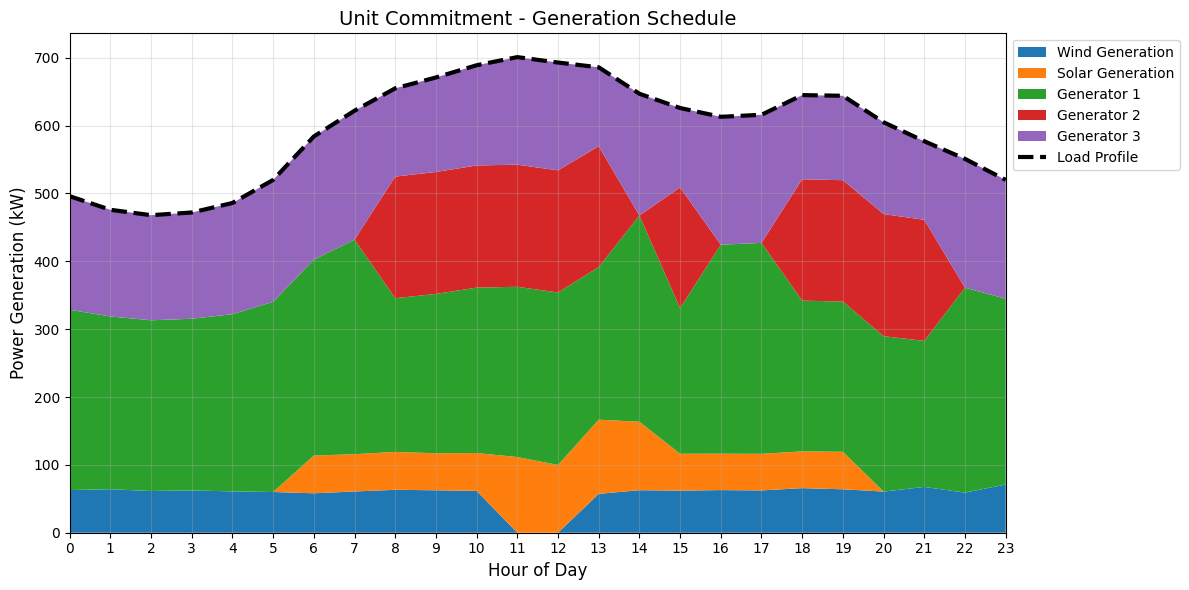

In [117]:
hours = sorted(model.T)

# Dispatchable Generation (using averaged values across all scenarios)
wind_gen = []
solar_gen = []
dispatchable_gen = {g: [] for g in gen_ids}

for t in hours:
    # Use averaged wind and solar generation
    wind_gen.append(u_wind[t] * wind_avg[t])
    solar_gen.append(u_solar[t] * solar_avg[t])

    # Use averaged dispatchable generation
    for g in gen_ids:
        dispatchable_gen[g].append(p_gen_data[g][t])


plt.figure(figsize=(12,6))

plt.stackplot(hours, wind_gen, solar_gen, dispatchable_gen[1], dispatchable_gen[2], dispatchable_gen[3],
              labels=['Wind Generation', 'Solar Generation', 'Generator 1', 'Generator 2', 'Generator 3'],
              colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])

plt.plot(hours, load_data, color='black', linewidth=3, label='Load Profile', linestyle='--')

plt.title("Unit Commitment - Generation Schedule", fontsize=14)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Power Generation (kW)", fontsize=12)
plt.xlim(0, 23)
plt.xticks(hours)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

### Export Results for Submission

In [ ]:
# Export results in required format
submission_data = {
    'name': 'Team_B',
    'task': DATA  # 'B' or 'C' depending on dataset
}

# Add binary on/off schedules for each generator dynamically
for idx, g in enumerate(gen_ids, 1):
    submission_data[f'u{idx}'] = [int(u_gen_data[g][t]) for t in range(24)]

# Add power generation schedules for each generator dynamically
for idx, g in enumerate(gen_ids, 1):
    submission_data[f'p{idx}'] = [float(p_gen_data[g][t]) for t in range(24)]

# Add renewable schedules
submission_data['uwind'] = [int(u_wind[t]) for t in range(24)]
submission_data['usolar'] = [int(u_solar[t]) for t in range(24)]

# Save to JSON file
submission_file = os.path.join(results_dir, f"Competition_5_Group_B.json")
with open(submission_file, 'w') as f:
    json.dump(submission_data, f, indent=2)

print(f"\n{'='*90}")
print(f"SUBMISSION FILE EXPORTED")
print(f"{'='*90}")
print(f"Team: {submission_data['name']}")
print(f"Task: {submission_data['task']}")
print(f"Dataset: Data{DATA}")
print(f"Number of generators: {len(gen_ids)}")
print(f"File: {submission_file}")
print(f"{'='*90}")

# Display the data structure
print("\nSubmission data preview:")
for key, value in submission_data.items():
    if isinstance(value, list):
        print(f"{key}: {value[:5]}... (length: {len(value)})")
    else:
        print(f"{key}: {value}")



SUBMISSION FILE EXPORTED
Team: Team_B
Task: B
File: Results\Competition_5_Group_B.json

Submission data preview:
name: Team_B
task: B
u1: [1, 1, 1, 1, 1]... (length: 24)
u2: [0, 0, 0, 0, 0]... (length: 24)
u3: [1, 1, 1, 1, 1]... (length: 24)
p1: [265.7488000000022, 254.65440000000203, 251.6432000000018, 252.97439999999818, 261.2192000000022]... (length: 24)
p2: [0.0, 0.0, 0.0, 0.0, 0.0]... (length: 24)
p3: [167.37119999999962, 157.22559999999993, 154.8767999999987, 156.62560000000133, 163.9007999999997]... (length: 24)
uwind: [1, 1, 1, 1, 1]... (length: 24)
usolar: [0, 0, 0, 0, 0]... (length: 24)
